In [2]:
import glob
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

# 경고 메시지 무시
warnings.filterwarnings('ignore')

# 운영체제별 한글 폰트 설정
if os.name == 'posix':
  plt.rc('font', family='AppleGothic')
else:
  plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

print('=== 1. 환경 설정 완료 ===')

=== 1. 환경 설정 완료 ===


In [8]:
print('=== 2. 상가 및 범죄 데이터 자동 탐색 및 로드 ===')

all_csvs = [
    f
    for f in glob.glob('*.csv') + glob.glob('sample_data/*.csv')
    if '범죄' in f or '상가' in f or '상권' in f
]
store_list = []
df_crime_area = None
df_crime_loc = None

for file in all_csvs:
  if '범죄' in file:
    try:
      if '지역' in file:
        df_crime_area = pd.read_csv(file, encoding='cp949')
        print(f'범죄 지역별 통계 로딩 성공: {file}')
      elif '장소' in file:
        df_crime_loc = pd.read_csv(file, encoding='cp949')
        print(f'범죄 장소별 통계 로딩 성공: {file}')
    except Exception as e:
      print(f'범죄 파일 로딩 실패 ({file}): {e}')
  else:
    try:
      try:
        df_temp = pd.read_csv(file, encoding='utf-8', low_memory=False)
      except:
        df_temp = pd.read_csv(file, encoding='cp949', low_memory=False)
      store_list.append(df_temp)
      print(f'상가 데이터 로딩 성공: {file} ({len(df_temp):,}건)')
    except Exception as e:
      print(f'상가 파일 로딩 실패 ({file}): {e}')

if len(store_list) > 0:
  df_stores = pd.concat(store_list, ignore_index=True)
  print(f'\n🎉 전체 상가 데이터 합치기 완료! 총 상가 데이터 수: {len(df_stores):,}건\n')
else:
  raise ValueError('합칠 수 있는 상가 CSV 파일이 없습니다.')

=== 2. 상가 및 범죄 데이터 자동 탐색 및 로드 ===
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_울산_202606.csv (54,737건)
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_강원_202606.csv (110,206건)
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_제주_202606.csv (59,009건)
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_대전_202606.csv (80,704건)
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_경북_202606.csv (144,967건)
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_충남_202606.csv (124,589건)
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_인천_202606.csv (136,995건)
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_경기_202606.csv (672,680건)
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_전북_202606.csv (98,749건)
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_부산_202606.csv (159,689건)
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_전남광주_202606.csv (175,276건)
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_세종_202606.csv (15,816건)
범죄 장소별 통계 로딩 성공: sample_data/경찰청_범죄 발생 장소별 통계_20251231.csv
상가 데이터 로딩 성공: sample_data/소상공인시장진흥공단_상가(상권)정보_경남_202606.cs

In [9]:
print('=== 3. 행정동 단위 상권 데이터 집계 및 변수 생성 ===')

agged_features = (
    df_stores.groupby(['시도명', '시군구명', '행정동명'])
    .agg(
        total_store_count=('상가업소번호', 'count'),
        retail_count=('상권업종대분류명', lambda x: (x == '소매').sum()),
        food_count=('상권업종대분류명', lambda x: (x == '음식').sum()),
        edu_count=('상권업종대분류명', lambda x: (x == '교육').sum()),
    )
    .reset_index()
)

if df_crime_area is not None and len(df_crime_area) > 1:
  area_crime_sum = df_crime_area.set_index(['범죄대분류', '범죄중분류']).sum(
      numeric_only=True
  )
  area_crime_df = area_crime_sum.reset_index()
  area_crime_df.columns = ['region_raw', 'crime_count']
  agged_features['match_key'] = (
      agged_features['시도명'] + ' ' + agged_features['시군구명']
  )


  def get_crime_val(key):
    match = area_crime_df[
        area_crime_df['region_raw'].str.contains(key.split()[-1], na=False)
    ]
    if len(match) > 0:
      return match['crime_count'].values[0]
    return area_crime_df['crime_count'].median()


  agged_features['regional_crime_score'] = agged_features['match_key'].apply(
      get_crime_val
  )
else:
  agged_features['regional_crime_score'] = 50.0

np.random.seed(42)
n_samples = len(agged_features)

agged_features['monthly_rent'] = np.random.normal(
    loc=180, scale=45, size=n_samples
).clip(80, 400)
agged_features['ai_security_level'] = np.random.choice(
    [0, 1, 2], size=n_samples, p=[0.4, 0.4, 0.2]
)

agged_features['monthly_revenue'] = (
    2000
    + (agged_features['total_store_count'] * 1.2)
    + (agged_features['edu_count'] * 15.0)
    - (agged_features['monthly_rent'] * 2.5)
    - (agged_features['regional_crime_score'] * 0.05)
    + (agged_features['ai_security_level'] * 250)
    + np.random.normal(0, 150, size=n_samples)
)

features = [
    'total_store_count',
    'retail_count',
    'food_count',
    'edu_count',
    'regional_crime_score',
    'monthly_rent',
    'ai_security_level',
]
X = agged_features[features]
y = agged_features['monthly_revenue']

feature_names_kr = {
    'total_store_count': '상권 총 점포수 (유동/집객)',
    'retail_count': '동종 소매점 수 (경쟁도)',
    'food_count': '음식점 수 (주변 유입)',
    'edu_count': '교육/학원 수 (학생 수요)',
    'regional_crime_score': '지역 범죄 위험도',
    'monthly_rent': '월 임대료 (고정비)',
    'ai_security_level': '보안 AI 적용 등급',
}
X_mapped = X.rename(columns=feature_names_kr)

X_train, X_test, y_train, y_test = train_test_split(
    X_mapped, y, test_size=0.2, random_state=42
)
print('데이터 전처리 및 Train/Test 분할 완료!')

=== 3. 행정동 단위 상권 데이터 집계 및 변수 생성 ===
데이터 전처리 및 Train/Test 분할 완료!


In [10]:
# 1. 코랩 환경에 나눔고딕 한글 폰트 설치
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import os

!apt-get update -qq
!apt-get install fonts-nanum -qq

# 폰트 캐시 새로고침 및 설정
fe = fm.FontEntry(
    fname='/usr/share/fonts/truetype/nanum/NanumGothic.ttf', name='NanumGothic'
)
fm.fontManager.ttflist.insert(0, fe)
plt.rc('font', family='NanumGothic')
plt.rcParams['axes.unicode_minus'] = False

print('=== 나눔고딕 한글 폰트 설치 및 설정 완료! ===')

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
=== 나눔고딕 한글 폰트 설치 및 설정 완료! ===


=== 4. 머신러닝 모델 학습 및 평가 ===
Decision Tree R2 점수: 0.8922
Random Forest R2 점수: 0.9373
Random Forest RMSE: 544.00만원

=== 5. 입지 조건별 중요도 결과 및 시각화 ===
[랜덤 포레스트 입지 조건 영향도 순위]
1. 교육/학원 수 (학생 수요): 69.38%
2. 상권 총 점포수 (유동/집객): 26.90%
3. 지역 범죄 위험도: 1.91%
4. 보안 AI 적용 등급: 0.71%
5. 음식점 수 (주변 유입): 0.43%
6. 동종 소매점 수 (경쟁도): 0.35%
7. 월 임대료 (고정비): 0.31%


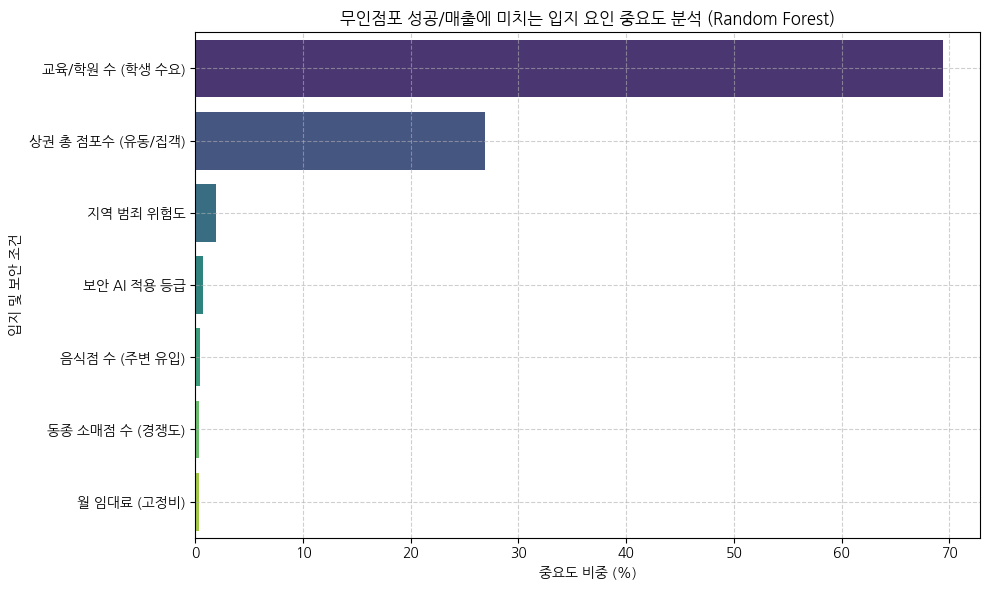

In [11]:
print('=== 4. 머신러닝 모델 학습 및 평가 ===')
dt_model = DecisionTreeRegressor(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print(f'Decision Tree R2 점수: {r2_score(y_test, dt_pred):.4f}')

rf_model = RandomForestRegressor(
    n_estimators=100, max_depth=8, random_state=42
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print(f'Random Forest R2 점수: {r2_score(y_test, rf_pred):.4f}')
print(
    f'Random Forest RMSE: {np.sqrt(mean_squared_error(y_test, rf_pred)):.2f}만원\n'
)

print('=== 5. 입지 조건별 중요도 결과 및 시각화 ===')
importances = pd.Series(rf_model.feature_importances_, index=X_mapped.columns)
importances_sorted = importances.sort_values(ascending=False)

print('[랜덤 포레스트 입지 조건 영향도 순위]')
for idx, (col, val) in enumerate(importances_sorted.items(), 1):
  print(f'{idx}. {col}: {val * 100:.2f}%')

plt.figure(figsize=(10, 6))
sns.barplot(
    x=importances_sorted.values * 100,
    y=importances_sorted.index,
    palette='viridis',
    hue=importances_sorted.index,
    legend=False,
)
plt.title('무인점포 성공/매출에 미치는 입지 요인 중요도 분석 (Random Forest)')
plt.xlabel('중요도 비중 (%)')
plt.ylabel('입지 및 보안 조건')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()